In [ ]:
import pandas as pd

df = pd.read_excel("cs-training.xlsx", index_col=0)
print(df.shape)
df.head()

(150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [ ]:
df.isnull().sum()
print((df["age"] == 0).sum())
print((df["NumberOfTimes90DaysLate"] >= 96).sum())
df.groupby(df["MonthlyIncome"].isnull())["SeriousDlqin2yrs"].mean()
df.groupby(df["MonthlyIncome"].isnull())["DebtRatio"].median()

1
269


,DebtRatio
MonthlyIncome,
False,0.296023
True,1159.000000


1. Missing income (NA)
Rows 8, 10 and 18 have NA under MonthlyIncome. Row 10 is also missing NumberOfDependents.

2. Row 16 has an income of 0.
Zero income is possible, but it is a data-quality flag.

3. Look at the DebtRatio next to each NA.

Row 8: DebtRatio = 5,710, income = NA

Row 10: DebtRatio = 46, income = NA

Row 16: DebtRatio = 477, income = 0

Row 18: DebtRatio = 2,058, income = NA

These are not ratios. DebtRatio should be a number like 0.3 (debt payments are 30% of income). When income is missing or zero, the column seems to hold the raw debt amount instead. I checked the full file:

    Median DebtRatio

Income known	0.30 (sensible)

Income missing	1,159 (nonsense as a ratio)

Of the 35,137 rows where DebtRatio is above 1, 29,425 (84%) are rows with missing or zero income. So the extreme DebtRatio values are mostly a side effect of missing income, not real people with absurd debt.

A DebtRatio above 1 would mean debt payments exceed income, which is rare. Here it mostly means “income is unknown.”

Note: people with missing income default slightly less (5.6%) than people with known income (6.95%). So missing income is not a red flag for default in this data. It is simply a group to handle carefully.

    Result	What it means
1 :	One row has age = 0. It’s a data error, so we’ll drop it.

269	: 269 rows have 96 or 98 in the “90 days late” column. These are special codes, not real counts.

Median DebtRatio when income is known	: 0.296, a sensible ratio

Median DebtRatio when income is missing :	1,159, so DebtRatio is unreliable when income is missing

In [ ]:
from sklearn.model_selection import train_test_split

# Remove the impossible age first
df = df[df["age"] >= 18]

X = df.drop(columns="SeriousDlqin2yrs")
y = df["SeriousDlqin2yrs"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(104999, 10) (45000, 10)
0.06683873179744569 0.06684444444444444


The most important rule: split first, clean second. If we compute things like the median income on the full dataset before splitting, information from the test set leaks into training. That’s data leakage, the one interviewers ask about. So we split first and learn every cleaning rule from the training set only.

Code does:

1] df[df["age"] >= 18] keeps only adults, which drops the age-0 row.

2] X holds the inputs and y the answer (default or not).

3] test_size=0.3 puts 30% of the data aside for the final exam.

4] random_state=42 makes the split the same every time you run it.

5] stratify=y keeps the default rate about 6.7% in both parts. This matters because defaults are rare.

In [ ]:
print("Default rate:")
print(df["SeriousDlqin2yrs"].mean())

print("\nMissing values:")
print(df.isnull().sum())

print("\nShare of income missing:")
print(df["MonthlyIncome"].isnull().mean())

print("\nDefault rate for the 269 special-code rows:")
special = df["NumberOfTimes90DaysLate"] >= 96
print(df.loc[special, "SeriousDlqin2yrs"].mean())

print("\nDefault rate for everyone else:")
print(df.loc[~special, "SeriousDlqin2yrs"].mean())

Default rate:
0.06684

Missing values:
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

Share of income missing:
0.19820666666666667

Default rate for the 269 special-code rows:
0.5464684014869888

Default rate for everyone else:
0.06597832112254644


You should see roughly:

Default rate about 0.0668 (6.7%)

MonthlyIncome missing 29,731 (19.8% of rows)

NumberOfDependents missing 3,924

Share of income missing about 0.198

Special-code default rate about 0.546 (54.6%)

Everyone else about 0.066 (6.6%)

In [ ]:
from sklearn.model_selection import train_test_split

# Remove the one impossible row (age 0)
df = df[df["age"] >= 18]

# X = the inputs, y = the answer we want to predict
X = df.drop(columns="SeriousDlqin2yrs")
y = df["SeriousDlqin2yrs"]

# 70% to learn from, 30% kept hidden for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Default rate in training:", y_train.mean())
print("Default rate in test:", y_test.mean())

Training set: (104999, 10)
Test set: (45000, 10)
Default rate in training: 0.06683873179744569
Default rate in test: 0.06684444444444444


What to expect:

Training set: about (104,999, 10)

Test set: about (45,000, 10)

Both default rates: about 0.0668

Why this matters: the test set is like a final exam. The model never sees it while learning, so its score on that set is an honest measure of how it would do on new borrowers. And we split before cleaning, so that nothing from the test data influences the cleaning rules.

Two questions for your notes

Write your answers in your own words. They are likely interview questions:

Why do we split before filling in missing values?
Why does stratify=y matter when only 6.7% of borrowers default?

Both parts have the same default rate, which is what stratify does. The test set is now locked away, and we won’t touch it until the model is finished.

In [ ]:
codes = ["NumberOfTime30-59DaysPastDueNotWorse",
         "NumberOfTime60-89DaysPastDueNotWorse",
         "NumberOfTimes90DaysLate"]

# STEP A: learn the cleaning rules from TRAINING data only
valid_dr = X_train.loc[X_train["MonthlyIncome"].notna() &
                       (X_train["MonthlyIncome"] > 0), "DebtRatio"]
params = {
    "income_median": X_train["MonthlyIncome"].median(),
    "dep_median":    X_train["NumberOfDependents"].median(),
    "debt_median":   valid_dr.median(),
    "util_cap":      X_train["RevolvingUtilizationOfUnsecuredLines"].quantile(0.99),
    "debt_cap":      valid_dr.quantile(0.99),
    "income_cap":    X_train["MonthlyIncome"].quantile(0.99),
}
print(params)

# STEP B: a reusable cleaning function
def clean(d, p):
    d = d.copy()

    # special codes: flag first, then replace
    d["special_code"] = (d["NumberOfTimes90DaysLate"] >= 96).astype(int)
    for c in codes:
        d.loc[d[c] >= 96, c] = 0

    # income: flag, fix DebtRatio, then fill
    d["income_missing"] = d["MonthlyIncome"].isna().astype(int)
    bad_dr = d["MonthlyIncome"].isna() | (d["MonthlyIncome"] == 0)
    d.loc[bad_dr, "DebtRatio"] = p["debt_median"]
    d["MonthlyIncome"] = d["MonthlyIncome"].fillna(p["income_median"])
    d["NumberOfDependents"] = d["NumberOfDependents"].fillna(p["dep_median"])

    # cap outliers
    d["RevolvingUtilizationOfUnsecuredLines"] = d["RevolvingUtilizationOfUnsecuredLines"].clip(upper=p["util_cap"])
    d["DebtRatio"] = d["DebtRatio"].clip(upper=p["debt_cap"])
    d["MonthlyIncome"] = d["MonthlyIncome"].clip(upper=p["income_cap"])
    return d

# STEP C: apply to both sets with the SAME rules
X_train_c = clean(X_train, params)
X_test_c  = clean(X_test, params)

print("\nMissing values left in training:", X_train_c.isnull().sum().sum())
print("Missing values left in test:", X_test_c.isnull().sum().sum())
print("\nSpecial-code rows in training:", X_train_c["special_code"].sum())
print("\nMax values after cleaning:")
print(X_train_c.max())

{'income_median': 5400.0, 'dep_median': 0.0, 'debt_median': 0.2939756565, 'util_cap': np.float64(1.092958013280001), 'debt_cap': np.float64(3.0315547700199867), 'income_cap': np.float64(25000.0)}

Missing values left in training: 0
Missing values left in test: 0

Special-code rows in training: 184

Max values after cleaning:
RevolvingUtilizationOfUnsecuredLines        1.092958
age                                       109.000000
NumberOfTime30-59DaysPastDueNotWorse       13.000000
DebtRatio                                   3.031555
MonthlyIncome                           25000.000000
NumberOfOpenCreditLinesAndLoans            58.000000
NumberOfTimes90DaysLate                    17.000000
NumberRealEstateLoansOrLines               54.000000
NumberOfTime60-89DaysPastDueNotWorse       11.000000
NumberOfDependents                         13.000000
special_code                                1.000000
income_missing                              1.000000
dtype: float64


Phase 3: Clean the data

Each problem gets its own fix:

Problem:

1]269 special-code rows (96/98)

2]Missing income (20%)

3]DebtRatio is garbage when income is missing or 0

4]Missing dependents

5]Extreme outliers (utilization, DebtRatio, income)

Fix:

1]Add a flag column special_code, then replace 96/98 with 0

2]Add a flag column income_missing, then fill with the training median

3]Replace it with the median of the valid DebtRatio values

4]Fill with the training median

5]Cap at the 99th percentile


Why flags? Filling in a missing value hides the fact that it was missing. The flag keeps that information for the model. We saw that the special-code group defaults at 55%, so we definitely want the model to know about it.

Why the training median only? This is the data leakage rule. Every number used for cleaning is learned from the training set, then applied unchanged to the test set later.

What to expect

1]Missing values left: 0 in both sets.

2]Special-code rows in training: about 190 (269 × 0.7).

3]The maximum values should now be sensible. For example, the utilization maximum should be a small number, not 50,708.

The cleaning worked, and the output shows it:

1]Missing values left: 0 in both training and test.

2]Special-code rows in training: 184, close to my estimate of about 190.

3]Utilization: the maximum is now 1.09, down from 50,708.

4]DebtRatio: the maximum is now 3.03, down from 329,664.

5]MonthlyIncome: the maximum is now 25,000, down from about 3 million.

6]Two new columns: special_code and income_missing are both in the table, so the model can still see those groups.

The data is now ready for modelling. Training and test were cleaned with the same rules, and all the rules came from the training data only.

Phase 4: Which features are useful? (WoE and IV)

Before building the model, we measure how well each feature separates good borrowers from defaulters. This is how real scorecards are built.

Weight of Evidence (WoE) works on groups (bins) of a feature, such as age 18-25, age 26-35, and so on. For each bin it asks how many good borrowers there are compared with defaulters:

WoE = ln( % of all good borrowers in the bin ÷ % of all defaulters in the bin )

WoE above 0 means the bin is safer than average.
WoE below 0 means the bin is riskier than average.

Information Value (IV) adds up WoE across all bins into one score for the whole feature:

    IV	Predictive power
below 0.02 :	Useless

0.02 to 0.1	: Weak

0.1 to 0.3 :	Medium

0.3 to 0.5 :	Strong

above 0.5 :	Suspiciously strong (check for data leakage)

In [ ]:
count_cols = ["NumberOfTime30-59DaysPastDueNotWorse",
              "NumberOfTime60-89DaysPastDueNotWorse",
              "NumberOfTimes90DaysLate",
              "NumberRealEstateLoansOrLines",
              "NumberOfDependents"]

def prep(col):
    f = X_train_c[col]
    if col in count_cols:
        return f.clip(upper=3)           # groups: 0, 1, 2, 3+
    if f.nunique() <= 2:
        return f                          # binary flags
    return f

results = {}
for col in X_train_c.columns:
    f = prep(col)
    if f.nunique() <= 4:
        # few distinct values: use each value as its own group
        t = pd.DataFrame({"group": f, "bad": y_train})
        g = t.groupby("group")["bad"].agg(["count", "sum"])
        g["bad"] = g["sum"]; g["good"] = g["count"] - g["bad"]
        pg = (g["good"] + 0.5) / (g["good"].sum() + 0.5)
        pb = (g["bad"]  + 0.5) / (g["bad"].sum()  + 0.5)
        results[col] = ((pg - pb) * np.log(pg / pb)).sum()
    else:
        _, results[col] = woe_iv(f, y_train)

print(pd.Series(results).sort_values(ascending=False).round(3))

RevolvingUtilizationOfUnsecuredLines    1.109
NumberOfTimes90DaysLate                 0.845
NumberOfTime30-59DaysPastDueNotWorse    0.685
NumberOfTime60-89DaysPastDueNotWorse    0.556
age                                     0.242
DebtRatio                               0.075
MonthlyIncome                           0.068
NumberOfOpenCreditLinesAndLoans         0.067
NumberRealEstateLoansOrLines            0.056
special_code                            0.037
NumberOfDependents                      0.033
income_missing                          0.010
dtype: float64


Correct ranking

    Feature :	IV :	Strength

RevolvingUtilization :	1.109 :	Very strong

NumberOfTimes90DaysLate :	0.845 :	Very strong

NumberOfTime30-59DaysPastDue :	0.685 :	Very strong

NumberOfTime60-89DaysPastDue :	0.556 :	Very strong

age :	0.242 :	Medium

DebtRatio :	0.075 :	Weak

MonthlyIncome :	0.068 :	Weak

NumberOfOpenCreditLines :	0.067 :	Weak

NumberRealEstateLoans :	0.056 :	Weak

special_code :	0.037 :	Weak

NumberOfDependents :	0.033 :	Weak

income_missing :	0.010 :	Useless

What your age table tells you:

1]Riskiest: ages 21 to 33, with a bad rate of 11.2% and a WoE of -0.56. Safest: ages 72 and above, with a bad rate of 2.2% and a WoE of +1.15.

2]A lender would reasonably conclude that default risk falls steadily with age, so young borrowers need tighter limits or a higher interest rate. An Indian lender has to be careful here, though. Using age directly in a lending decision can raise fairness and regulatory questions. That is worth a line in your README.

What the utilization table tells you

Use the table from my check as your answer to question 2. Borrowers using under 5% of their credit have bad rates of about 1.4% to 2.5%. Those using 98% or more have a bad rate of 23.2%. People near their credit limit are stretched and far more likely to default, which is why utilization has the highest IV.

Phase 4: Build the baseline scorecard model

Two steps:

1]Convert each feature to WoE. Every value is replaced by the WoE of its group. Age 25 becomes -0.56 because that group is risky. The model then works with “how risky is this group” instead of raw numbers.

2]Fit a logistic regression on those WoE values and test it on the hidden 30%.

Bin edges and WoE values come from the training data only, and the same mapping is applied to the test set. That is the same no-leakage rule as before.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

Xtr, Xte = X_train_c, X_test_c
count_cols = ["NumberOfTime30-59DaysPastDueNotWorse",
              "NumberOfTime60-89DaysPastDueNotWorse",
              "NumberOfTimes90DaysLate",
              "NumberRealEstateLoansOrLines",
              "NumberOfDependents"]
features = [c for c in Xtr.columns if c != "income_missing"]   # drop useless feature

def make_groups(f, col, edges=None):
    if col in count_cols:          # groups 0, 1, 2, 3+
        return f.clip(upper=3), None
    if col == "special_code":      # already 0/1
        return f, None
    if edges is None:              # learn 10 bins from training data
        _, edges = pd.qcut(f, q=10, retbins=True, duplicates="drop")
        edges = edges.copy()
        edges[0], edges[-1] = -np.inf, np.inf
    return pd.cut(f, bins=edges), edges

# Learn bins and WoE from TRAINING data
woe_maps, edge_maps = {}, {}
W_train = pd.DataFrame(index=Xtr.index)
for col in features:
    g, edges = make_groups(Xtr[col], col)
    edge_maps[col] = edges
    t = pd.DataFrame({"g": g, "bad": y_train}).groupby("g", observed=False)["bad"].agg(["count", "sum"])
    bad = t["sum"]; good = t["count"] - bad
    pg = (good + 0.5) / (good.sum() + 0.5)
    pb = (bad + 0.5) / (bad.sum() + 0.5)
    woe_maps[col] = np.log(pg / pb)
    W_train[col] = g.map(woe_maps[col]).astype(float)

# Apply the SAME bins and WoE to the test data
W_test = pd.DataFrame(index=Xte.index)
for col in features:
    g, _ = make_groups(Xte[col], col, edge_maps[col])
    W_test[col] = g.map(woe_maps[col]).astype(float)

print("Missing after WoE:", W_train.isnull().sum().sum(), W_test.isnull().sum().sum())

# Fit logistic regression
lr = LogisticRegression(max_iter=1000)
lr.fit(W_train, y_train)

def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return (tpr - fpr).max()

for name, W, y in [("Train", W_train, y_train), ("Test", W_test, y_test)]:
    p = lr.predict_proba(W)[:, 1]
    auc = roc_auc_score(y, p)
    print(f"{name}: AUC={auc:.3f}  Gini={2*auc-1:.3f}  KS={ks_stat(y, p):.3f}")

Missing after WoE: 0 0
Train: AUC=0.858  Gini=0.715  KS=0.555
Test: AUC=0.858  Gini=0.717  KS=0.562


Questions for your notes
What does a Gini of 0.72 mean in plain words?
Why is it useful that the train and test scores are so close?

Next: turn probabilities into scores and risk bands

The model outputs a probability of default (PD), like 0.04. Lenders want a score like a CIBIL score, so we convert one into the other with the standard scorecard formula:

1]Base score: 600 at odds of 50 good borrowers for every 1 bad.

2]PDO (points to double the odds): 20. Every 20 extra points means the borrower is twice as likely to be good as bad.

3]Score = Offset + Factor × ln(good odds), with Factor = PDO ÷ ln 2 and Offset = 600 − Factor × ln 50.

In [ ]:
PDO, base_score, base_odds = 20, 600, 50
factor = PDO / np.log(2)
offset = base_score - factor * np.log(base_odds)

def to_score(W):
    p = lr.predict_proba(W)[:, 1]            # probability of default
    p = np.clip(p, 1e-6, 1 - 1e-6)
    score = offset + factor * np.log((1 - p) / p)
    return score, p

score_train, pd_train = to_score(W_train)
score_test,  pd_test  = to_score(W_test)

print(pd.Series(score_test).describe().round(1))

# Risk bands
edges  = [-np.inf, 540, 570, 590, 610, np.inf]
labels = ["E Very High", "D High", "C Medium", "B Low", "A Very Low"]

t = pd.DataFrame({"band": pd.cut(score_test, bins=edges, labels=labels),
                  "bad": y_test.values,
                  "pd": pd_test})
bands = t.groupby("band", observed=True).agg(
    borrowers=("bad", "size"),
    actual_bad_rate=("bad", "mean"),
    avg_predicted_pd=("pd", "mean"))
bands["share_of_portfolio"] = bands["borrowers"] / bands["borrowers"].sum()
print(bands.round(3))

count    45000.0
mean       583.5
std         34.5
min        409.7
25%        565.7
50%        592.5
75%        608.9
max        633.5
dtype: float64
             borrowers  actual_bad_rate  avg_predicted_pd  share_of_portfolio
band                                                                         
E Very High       4548            0.361             0.348               0.101
D High            8445            0.091             0.083               0.188
C Medium          8199            0.040             0.038               0.182
B Low            13320            0.016             0.020               0.296
A Very Low       10488            0.006             0.011               0.233


The scorecard works, and the bad rate climbs from 0.6% in band A to 36.1% in band E.

Answer to question 1

If a lender approves only bands A, B and C, it approves 71.1% of applicants (10,488 + 13,320 + 8,199 = 32,007 of 45,000). The bad rate among those approved is about 1.9%, against 6.7% for the whole population. By refusing the riskiest 29%, the lender cuts defaults by roughly two thirds.

The finance layer

The dataset has no loan amount, interest rate or recovery data, so we have to make assumptions. They are mine, not facts from the data. Say so in your README and in interviews.

    Assumption :	Value :	Meaning
1] EAD :	₹1,00,000 :	Every loan is ₹1 lakh for 1 year

2] LGD :	60% :	Unsecured loan, so 60% is lost when a borrower defaults

3] Margin on a good loan :	₹10,000 :	Interest earned minus funding and operating costs

In [16]:
score_arr = np.asarray(score_test)
y_arr = np.asarray(y_test)

rows = []
for c in range(480, 631, 10):
    approved = score_arr >= c
    n = approved.sum()
    bad = y_arr[approved].sum()
    good = n - bad
    profit = good * MARGIN - bad * LGD * EAD
    rows.append((c, n / len(y_arr), bad / n, profit / 1e7))

res = pd.DataFrame(rows, columns=["cutoff", "approval_rate", "bad_rate", "profit_cr"])
print(res.round(3).to_string(index=False))

best = res.loc[res["profit_cr"].idxmax()]
print("Best cutoff:", int(best["cutoff"]),
      "| approval rate:", round(best["approval_rate"], 3),
      "| bad rate:", round(best["bad_rate"], 3),
      "| profit (Rs crore):", round(best["profit_cr"], 2))

 cutoff  approval_rate  bad_rate  profit_cr
    480          0.983     0.058     26.290
    490          0.975     0.054     27.224
    500          0.967     0.051     28.053
    510          0.957     0.047     28.877
    520          0.942     0.043     29.668
    530          0.923     0.038     30.420
    540          0.899     0.034     30.883
    550          0.857     0.029     30.696
    560          0.790     0.023     29.821
    570          0.711     0.019     27.842
    580          0.628     0.015     25.334
    590          0.529     0.011     21.932
    600          0.397     0.008     16.870
    610          0.233     0.006     10.068
    620          0.083     0.005      3.590
    630          0.007     0.009      0.300
Best cutoff: 540 | approval rate: 0.899 | bad rate: 0.034 | profit (Rs crore): 30.88


The best cutoff at 540 (89.9% approved, 3.4% bad rate, ₹30.88 crore profit). The finance layer is done. That is the part of the project most freshers don’t have.

Phase 5: Compare with XGBoost

So far the model is logistic regression. XGBoost is a more powerful model that builds many small decision trees, each one correcting the mistakes of the previous ones. It finds non-linear patterns and interactions that logistic regression can’t. The question lenders ask is whether the extra power is worth giving up explainability.

XGBoost doesn’t need the WoE step, so it uses the cleaned data directly.

In [17]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,      # number of trees
    max_depth=3,           # keep each tree shallow to avoid overfitting
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="auc",
    random_state=42,
)
xgb.fit(X_train_c, y_train)

for name, Xd, y in [("Train", X_train_c, y_train), ("Test", X_test_c, y_test)]:
    p = xgb.predict_proba(Xd)[:, 1]
    auc = roc_auc_score(y, p)
    print(f"XGBoost {name}: AUC={auc:.3f}  Gini={2*auc-1:.3f}  KS={ks_stat(y, p):.3f}")

XGBoost Train: AUC=0.872  Gini=0.743  KS=0.586
XGBoost Test: AUC=0.867  Gini=0.734  KS=0.576


How to interpret it ?

This small gap is a good result for your project. A bank has to explain every decision to customers and regulators, and a logistic regression scorecard is easy to explain: each feature adds or subtracts points. For about 0.9 points of AUC, many lenders would keep the scorecard as the main model. They might use XGBoost as a challenger model or as a check.

A good interview answer:

“XGBoost gave a Gini of 0.73 against 0.72 for the scorecard. The gain was small, so I would deploy the scorecard for explainability and keep XGBoost as a challenger.” Note that this is a result from this dataset. Gaps can be bigger on richer data.

Questions for your notes

Q1] Would you deploy XGBoost or the scorecard, and why?

Q2] Why do train and test scores being close matter for both models?

Open items

Whenever you’re ready, write answers to these, since interviewers love them:

q1] Why do we split before filling missing values?

q2] Why does stratify matter?

q3] What does a Gini of 0.72 mean?

q4]What happens to the best cutoff if LGD rises to 75%? (Change LGD = 0.75, rerun both cells, and see.)

Phase 5b: Explain the model with SHAP

XGBoost is harder to explain than a scorecard, so we use SHAP to see what drives its predictions. For each borrower, SHAP gives each feature a number: how much it pushed that borrower’s risk up or down. Regulators and credit committees expect this kind of explanation for any non-trivial model.

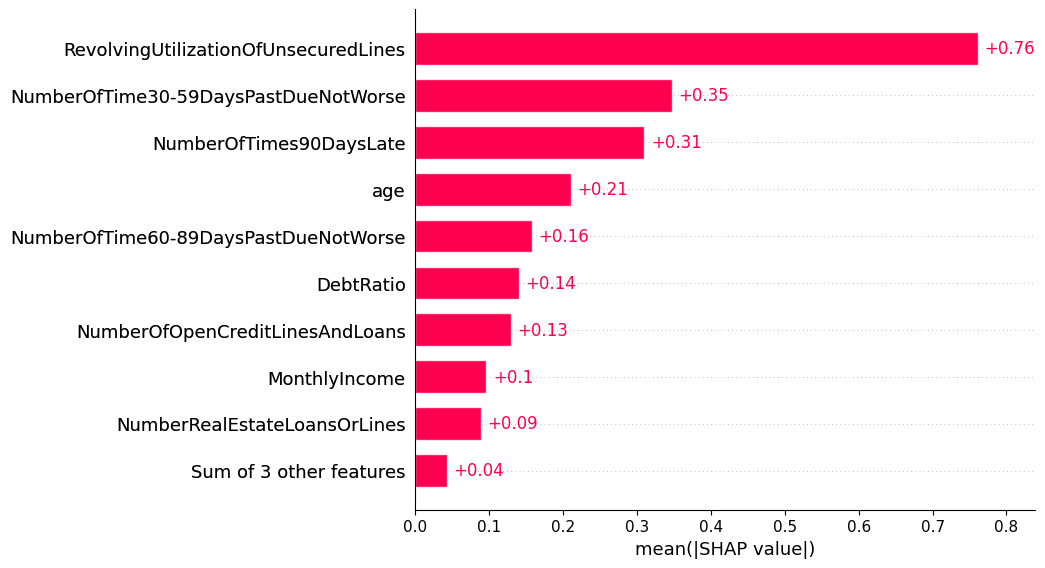

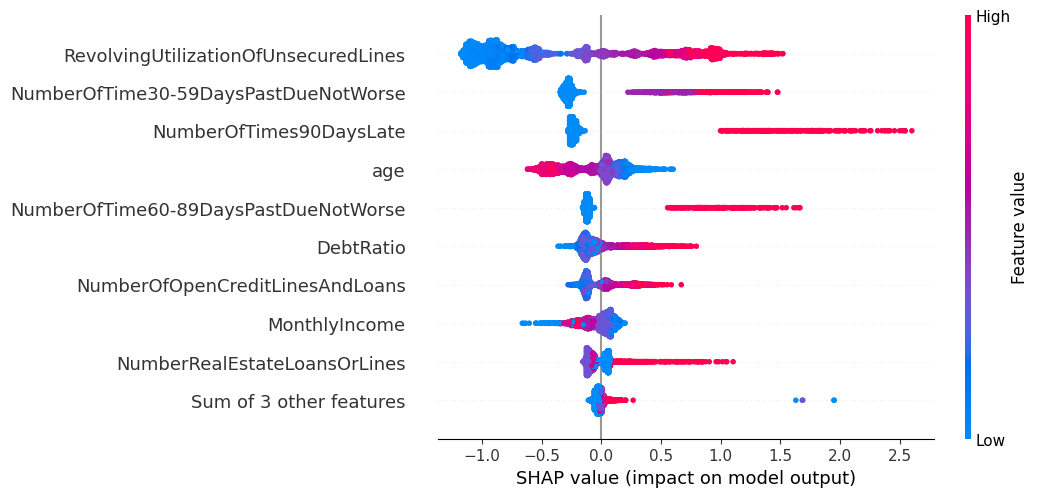

Predicted default probability: 0.869


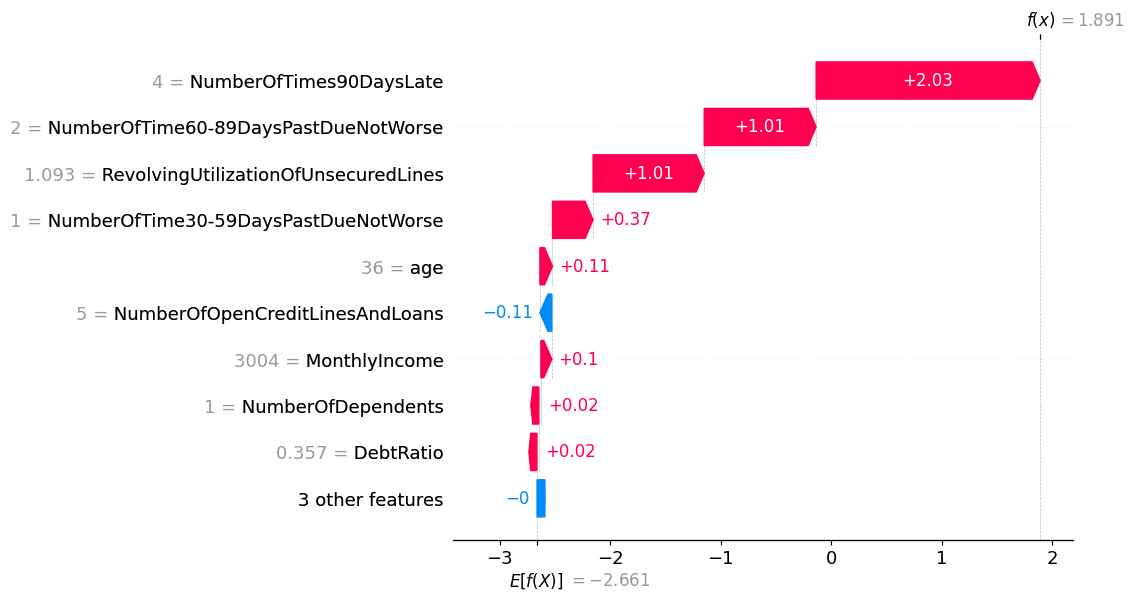

In [18]:
import shap
import matplotlib.pyplot as plt

# SHAP on a 5,000-row sample of the TEST set (faster, same story)
X_sample = X_test_c.sample(5000, random_state=42)
explainer = shap.TreeExplainer(xgb)
sv = explainer(X_sample)

# 1) Overall importance
shap.plots.bar(sv, show=True)

# 2) Direction of each feature's effect
shap.plots.beeswarm(sv, show=True)

# 3) Explain ONE borrower: the riskiest one in the sample
i = int(np.argmax(xgb.predict_proba(X_sample)[:, 1]))
print("Predicted default probability:", round(xgb.predict_proba(X_sample)[i, 1], 3))
shap.plots.waterfall(sv[i], show=True)

Here is how to read them.

1. Bar chart: what matters most

Utilization is the biggest driver (+0.76) by a wide margin. Late payments come next (30-59 days at +0.35, 90+ days at +0.31), then age (+0.21). This matches the IV ranking and the scorecard coefficients, so three different methods agree.

2. Beeswarm: the direction of each effect

Red dots are high feature values and blue dots are low ones. Dots to the right raise predicted risk.

1]Utilization: red dots sit on the right, so high utilization raises risk and low utilization lowers it.

2]Late payments (30-59, 60-89, 90+): the red dots are far to the right, and the 90+ days column has the biggest push (up to about +2.5). Any serious delinquency is a strong warning sign.

3]Age: it is the reverse. Red (older) dots sit on the left and blue (younger) dots on the right, so older borrowers are safer and younger ones riskier, as in your WoE table.

4]DebtRatio and open credit lines: red dots lean right, so more debt and more credit lines mean higher risk.

5]MonthlyIncome: the pattern is mixed and less clean. It’s a weak feature (IV 0.068), so don’t build a story around it.

3. Waterfall: why this one borrower scored 86.9%

The chart starts at the average borrower and adds each feature’s push:

    Feature :	Value :	Effect on risk
1] 90+ days : late	4 times :	+2.03

2] 60-89 days : late	2 times :	+1.01

3] Utilization :	1.093 (over limit) :	+1.01

4] 30-59 days late :	1 time :	+0.37

5] Age :	36 :	+0.11

The starting point is E[f(X)] = −2.661 and the end is f(x) = 1.891. These are log-odds, not probabilities. Convert them with 1 ÷ (1 + e^−x):

1] Start: 1 ÷ (1 + e^2.661) ≈ 6.5%, the average default rate.

2] End: 1 ÷ (1 + e^−1.891) ≈ 86.9%, matching the printed probability.

You can answer “why was this person rejected?” in one sentence: “Four 90-day delinquencies, two 60-day delinquencies, and a credit line used beyond its limit.”

Answers to your notes questions

1] Direction: high utilization pushes risk up, and high age pushes risk down.

2] Why explain rejections: customers are entitled to know why they were declined, and regulators and credit committees expect lenders to justify decisions. This is one reason scorecards remain popular. SHAP lets you explain a more complex model too.

Phase 7: Package the project

For the dashboard and GitHub, the trained model has to be saved to a file, because Colab forgets everything when it restarts. Paste this into a new cell. It bundles everything the dashboard needs:

In [19]:
import joblib

artifacts = {
    "params": params,            # cleaning rules from training data
    "codes": codes,
    "count_cols": count_cols,
    "features": features,
    "edge_maps": edge_maps,      # WoE bin edges
    "woe_maps": woe_maps,        # WoE value per bin
    "lr": lr,                    # logistic regression scorecard
    "xgb": xgb,                  # XGBoost challenger
    "factor": factor,
    "offset": offset,
    "band_edges": [-np.inf, 540, 570, 590, 610, np.inf],
    "band_labels": ["E Very High", "D High", "C Medium", "B Low", "A Very Low"],
}
joblib.dump(artifacts, "scorecard_artifacts.joblib")
print("Saved")

Saved
